# Das erste Netz in PyTorch, Schritt für Schritt erklärt

Dieses Notebook begleitet das Buch *Modern Computer Vision with PyTorch*, Kapitel 2, S. 52–63. Es ist derselbe Code, den ihr in der Stunde am 17.11. selbst geschrieben habt, aber jede Zeile ist auf Deutsch erklärt.

**So benutzt ihr es:** Lest zuerst den Text über einer Zelle, überlegt, was herauskommen wird, und führt die Zelle dann aus (Umschalt + Enter). Die Zellen der Reihe nach ausführen, von oben nach unten. Bei jedem Abschnitt steht die Buchseite, auf der ihr dasselbe auf Englisch findet.

**Die Aufgabe des Netzes:** Es bekommt zwei Zahlen und soll ihre Summe ausgeben. Wir sagen ihm die Regel aber nicht. Es bekommt nur vier Beispiele:

| Eingabe | richtige Ausgabe |
|---|---|
| 1 und 2 | 3 |
| 3 und 4 | 7 |
| 5 und 6 | 11 |
| 7 und 8 | 15 |

Am Ende fragen wir: Was sagt das Netz zu 10 und 11?

**Die fünf Schritte**, die in jedem Netz wieder vorkommen:

1. Daten als Tensoren anlegen
2. Das Netz bauen
3. Verlustfunktion und Optimierer festlegen
4. Trainieren
5. Für neue Daten vorhersagen

Oben rechts im Notebook muss als Kernel die Umgebung `realsense` stehen, sonst kennt Python `torch` nicht.

## 0 Bibliotheken laden

- `torch` ist PyTorch selbst: Tensoren und das Rechnen damit.
- `torch.nn` (kurz `nn`) enthält die fertigen Bausteine für Netze: Schichten, Aktivierungen, Verlustfunktionen.
- `SGD` ist der Optimierer, der die Gewichte verstellt (S. 57).
- `matplotlib` zeichnet am Ende die Verlaufskurve.

In [1]:
import torch
import torch.nn as nn
from torch.optim import SGD
import matplotlib.pyplot as plt

## 1 Die Daten als Tensoren (S. 52–53)

`x` sind die Eingaben, `y` die richtigen Ausgaben. Jede Zeile ist ein Beispiel: `[1, 2]` gehört zu `[3]`.

Beachtet: Auch `y` besteht aus Listen mit je einer Zahl, also `[[3], [7], ...]` und nicht `[3, 7, ...]`. Das Netz gibt für jedes Beispiel eine Zeile mit einer Zahl aus, und `y` muss dieselbe Form haben.

In [2]:
x = [[1, 2], [3, 4], [5, 6], [7, 8]]
y = [[3], [7], [11], [15]]

`torch.tensor(...)` macht aus der Python-Liste einen Tensor. Was ist der `dtype`, also die Art der Zahlen?

In [3]:
print(torch.tensor(x).dtype)

torch.int64


`int64` heißt: ganze Zahlen. Ein Netz rechnet aber mit Kommazahlen, denn seine Gewichte sind Kommazahlen wie 0,37 und werden beim Lernen in kleinen Schritten verstellt (S. 53, erster Absatz). Deshalb hängen wir `.float()` an. Dann ist der `dtype` `float32`.

Wer `.float()` vergisst, bekommt später beim Rechnen die Fehlermeldung `mat1 and mat2 must have the same dtype, but got Long and Float`.

Großes `X` und `Y` sind die Tensoren, kleines `x` und `y` bleiben die Listen.

In [4]:
X = torch.tensor(x).float()
Y = torch.tensor(y).float()
print("X:", X.shape, X.dtype)
print("Y:", Y.shape, Y.dtype)

X: torch.Size([4, 2]) torch.float32
Y: torch.Size([4, 1]) torch.float32


`shape` liest man so: `X` hat 4 Zeilen (4 Beispiele) und 2 Spalten (2 Eingaben je Beispiel). `Y` hat 4 Zeilen und 1 Spalte.

### Das Gerät (S. 53)

PyTorch kann auf dem Prozessor (`cpu`) oder auf einer Grafikkarte mit CUDA (`cuda`) rechnen. Die Zeile fragt nach, ob eine passende Grafikkarte da ist, und nimmt sonst den Prozessor. Auf den Schulrechnern kommt `cpu` heraus. Für vier Beispiele ist das völlig egal; bei Tausenden von Fotos ist die Grafikkarte viel schneller, weil sie viele Zahlen gleichzeitig rechnet.

`.to(device)` legt die Tensoren auf dieses Gerät. Daten und Netz müssen auf demselben Gerät liegen.

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
X = X.to(device)
Y = Y.to(device)
print(device)

cpu


## 2 Das Netz als Klasse (S. 53–56)

Unser Netz hat drei Teile:

- **2 Eingänge → 8 Neuronen:** `nn.Linear(2, 8)`. Jedes der 8 Neuronen rechnet *Eingabe 1 · Gewicht + Eingabe 2 · Gewicht + Bias*.
- **Aktivierung:** `nn.ReLU()` macht negative Werte zu 0 und lässt positive, wie sie sind. Ohne Aktivierung wären zwei lineare Schichten hintereinander wieder nur eine einzige lineare Rechnung.
- **8 Neuronen → 1 Ausgang:** `nn.Linear(8, 1)` fasst die 8 Werte zu einer Zahl zusammen, der Vorhersage.

In PyTorch schreibt man ein Netz als Klasse, die von `nn.Module` erbt. Die Klasse hat zwei Teile:

- In `__init__` werden die Schichten **angelegt**. Die erste Zeile muss `super().__init__()` sein: Sie richtet den Teil von `nn.Module` ein, der sich die Gewichte merkt. Fehlt sie, kommt `cannot assign module before Module.__init__() call`.
- In `forward` steht, in welcher **Reihenfolge** die Eingabe durch die Schichten läuft. `forward` ruft ihr nie selbst auf: `mynet(X)` ruft es für euch auf.

Die Namen wie `input_to_hidden_layer` sind frei gewählt und stammen aus dem Buch. Ihr dürft eure Schichten auch anders nennen.

In [6]:
class MyNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_to_hidden_layer = nn.Linear(2, 8)    # 2 Eingaenge -> 8 Neuronen
        self.hidden_layer_activation = nn.ReLU()        # negative Werte -> 0
        self.hidden_to_output_layer = nn.Linear(8, 1)   # 8 Neuronen -> 1 Ausgang

    def forward(self, x):
        x = self.input_to_hidden_layer(x)
        x = self.hidden_layer_activation(x)
        x = self.hidden_to_output_layer(x)
        return x

Jetzt legen wir ein Netz an. Die Gewichte werden dabei **zufällig** gewählt (Kasten S. 55). Damit bei allen dieselben Zahlen herauskommen wie in diesem Notebook, setzen wir vorher mit `torch.manual_seed(0)` den Zufall fest. Ohne diese Zeile bekommt jedes Team etwas andere Zahlen, und das ist kein Fehler.

In [7]:
torch.manual_seed(0)
mynet = MyNeuralNet().to(device)

### Wie viele Gewichte hat das Netz? (S. 55–56)

Erst selbst rechnen, dann nachsehen:

| Teil | Gewichte | Bias | zusammen |
|---|---|---|---|
| `nn.Linear(2, 8)` | 2 · 8 = 16 | 8 | 24 |
| `nn.ReLU()` | 0 | 0 | 0 |
| `nn.Linear(8, 1)` | 8 · 1 = 8 | 1 | 9 |
| **Netz** | | | **33** |

`mynet.parameters()` liefert alle Gewichte und Bias des Netzes nacheinander. Die Schleife zeigt von jedem Teil die `shape`.

In [8]:
print(mynet.input_to_hidden_layer.weight.shape)
for par in mynet.parameters():
    print(par.shape)

torch.Size([8, 2])
torch.Size([8, 2])
torch.Size([8])
torch.Size([1, 8])
torch.Size([1])


`(8, 2)` heißt: 8 Neuronen mit je 2 Gewichten. Dann folgen 8 Bias, 1 Neuron mit 8 Gewichten und 1 Bias. Zusammen 16 + 8 + 8 + 1 = 33. Diese 33 Zahlen verstellt das Netz beim Lernen, sonst nichts.

### Was sagt das Netz, bevor es gelernt hat?

In [9]:
print(mynet(X))

tensor([[-0.5966],
        [-1.1333],
        [-1.5898],
        [-2.0464]], grad_fn=<AddmmBackward0>)


Die Vorhersagen liegen weit neben 3, 7, 11 und 15, sie sind sogar negativ. Das ist richtig so: Die Gewichte sind ja noch zufällig.

Hinter jedem Wert steht `grad_fn=...`. Das heißt: PyTorch hat sich gemerkt, wie dieser Wert ausgerechnet wurde. Das braucht es gleich, um auszurechnen, wie die Gewichte verstellt werden müssen.

## 3 Verlustfunktion und Optimierer (S. 57–58)

### Verlust: Wie falsch ist das Netz?

Die **Verlustfunktion** misst mit einer einzigen Zahl, wie weit die Vorhersagen von den richtigen Werten entfernt sind. Wir nehmen den mittleren quadratischen Fehler (Mean Squared Error, `nn.MSELoss`):

1. für jedes Beispiel: Vorhersage minus richtiger Wert,
2. das Ergebnis quadrieren (damit Abweichungen nach unten nicht negativ zählen und große Fehler stärker zählen),
3. den Mittelwert über alle Beispiele bilden.

Je kleiner der Verlust, desto besser. 0 hieße: alles genau richtig.

In [10]:
loss_func = nn.MSELoss()
loss_value = loss_func(mynet(X), Y)
print(loss_value)

tensor(132.0424, grad_fn=<MseLossBackward0>)


Zur Kontrolle rechnen wir dasselbe selbst aus, genau nach den drei Schritten oben:

In [11]:
selbst = ((mynet(X) - Y) ** 2).mean()
print(selbst)

tensor(132.0424, grad_fn=<MeanBackward0>)


Beide Zahlen sind gleich. `nn.MSELoss` ist also nichts Geheimnisvolles, nur diese eine Zeile.

### Optimierer: Wer verstellt die Gewichte?

Der **Optimierer** verstellt die Gewichte so, dass der Verlust kleiner wird. `SGD` heißt *Stochastic Gradient Descent*, auf Deutsch Gradientenabstieg.

- `mynet.parameters()` sagt ihm, **welche** Zahlen er verstellen darf: die 33 Gewichte und Bias.
- `lr=0.001` ist die **Lernrate**: Sie legt fest, wie groß jeder Schritt ist. Zu groß, und das Netz springt über das Ziel hinaus. Zu klein, und es lernt sehr langsam.

In [12]:
opt = SGD(mynet.parameters(), lr=0.001)

### Ein einziger Lernschritt (S. 58 oben)

Ein Lernschritt besteht immer aus denselben vier Zeilen:

| Zeile | was sie tut |
|---|---|
| `opt.zero_grad()` | die Gradienten vom letzten Schritt löschen; PyTorch würde sie sonst aufaddieren |
| `loss_value = loss_func(mynet(X), Y)` | vorhersagen und messen, wie falsch das Netz ist |
| `loss_value.backward()` | für jedes der 33 Gewichte ausrechnen, in welche Richtung der Verlust kleiner wird (der Gradient) |
| `opt.step()` | jedes Gewicht ein Stück in diese Richtung schieben, so weit die Lernrate es erlaubt |

Wir machen einen Schritt und messen danach noch einmal. `.item()` holt die Zahl aus dem Tensor heraus, damit man sie bequem ausgeben kann.

In [13]:
print("Verlust vorher: ", loss_func(mynet(X), Y).item())

opt.zero_grad()
loss_value = loss_func(mynet(X), Y)
loss_value.backward()
opt.step()

print("Verlust nachher:", loss_func(mynet(X), Y).item())

Verlust vorher:  132.0424346923828


Verlust nachher: 121.02224731445312


Der Verlust ist kleiner geworden. Ein Schritt bringt nicht viel, aber die Richtung stimmt. Jetzt wiederholen wir das oft.

## 4 Trainieren (S. 58–59)

Wir legen das Netz neu an, damit es wieder bei den zufälligen Anfangsgewichten startet, und machen 50 Lernschritte. Ein Durchlauf über alle Trainingsdaten heißt **Epoche**. Weil wir hier alle vier Beispiele auf einmal nehmen, ist eine Epoche genau ein Lernschritt.

In `loss_history` sammeln wir nach jeder Epoche den Verlust, um ihn danach zu zeichnen. `_` als Schleifenvariable heißt: Die Nummer der Runde brauchen wir nicht.

Achtung beim eigenen Arbeiten: Wer die Zelle mit `mynet = MyNeuralNet()` nach dem Training noch einmal ausführt, hat wieder ein ungelerntes Netz.

In [14]:
torch.manual_seed(0)
mynet = MyNeuralNet().to(device)
opt = SGD(mynet.parameters(), lr=0.001)

loss_history = []
for _ in range(50):
    opt.zero_grad()
    loss_value = loss_func(mynet(X), Y)
    loss_value.backward()
    opt.step()
    loss_history.append(loss_value.item())

print("Verlust in Epoche 1: ", round(loss_history[0], 2))
print("Verlust in Epoche 50:", round(loss_history[-1], 2))

Verlust in Epoche 1:  132.04
Verlust in Epoche 50: 0.12


### Die Verlaufskurve (S. 59, Abb. 2.5)

Die Kurve zeigt, wie der Verlust von Epoche zu Epoche sinkt. Am Anfang fällt sie langsam, dann schnell, am Ende liegt sie fast bei 0. So sieht ein Training aus, das funktioniert. In DS 11 und DS 12 lest ihr an solchen Kurven ab, ob ein Training gut läuft.

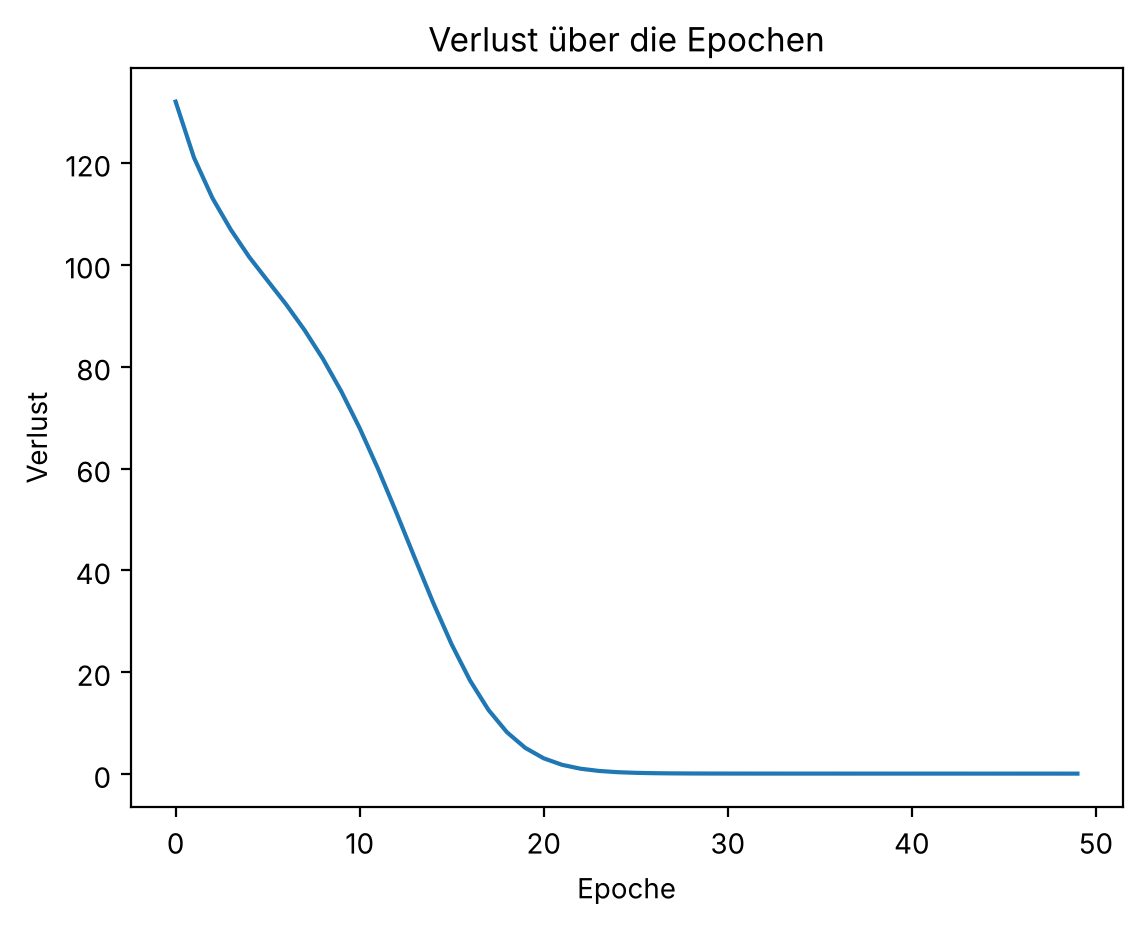

In [15]:
plt.plot(loss_history)
plt.title('Verlust über die Epochen')
plt.xlabel('Epoche')
plt.ylabel('Verlust')
plt.show()

## 5 Vorhersage für neue Daten (S. 62–63)

Jetzt die Frage der Stunde: Was sagt das Netz zu 10 und 11? Diese Zahlen kamen im Training nie vor.

Die neue Eingabe muss genauso aussehen wie die Trainingsdaten: eine Liste von Beispielen (deshalb die doppelten Klammern `[[10, 11]]`), als `float`, auf demselben Gerät.

In [16]:
val_x = [[10, 11]]
val_x = torch.tensor(val_x).float().to(device)
print(mynet(val_x))

tensor([[20.3312]], grad_fn=<AddmmBackward0>)


Das Netz sagt etwa 20,3 statt 21. Es hat die Regel „addieren“ nie gesehen, sondern nur vier Beispiele, und daraus eine Rechnung gelernt, die ungefähr passt. Mit einem anderen Seed kommt eine etwas andere Zahl heraus (zwischen etwa 20,1 und 21,0), denn das Netz startet mit anderen Zufallsgewichten (Kasten S. 55). Das Buch zeigt 20,99.

## 6 Dasselbe mit Dataset und DataLoader (S. 59–62)

Bisher haben wir in jedem Lernschritt alle Beispiele auf einmal ins Netz gegeben. Bei vier Zahlenpaaren geht das. Bei Tausenden von Fotos passt das nicht mehr auf einmal in den Speicher. Dann gibt man die Daten in kleinen **Stapeln** (englisch *batch*) ins Netz. Dafür hat PyTorch zwei Bausteine:

- Ein **Dataset** weiß, welche Beispiele es gibt, und liefert auf Nachfrage ein einzelnes Beispiel.
- Ein **DataLoader** holt sich aus dem Dataset Stapel von Beispielen, auf Wunsch jedes Mal neu gemischt.

Ein eigenes Dataset ist eine Klasse mit drei Methoden:

| Methode | macht oder liefert |
|---|---|
| `__init__` | bekommt Eingaben und Ziele und legt sie als `float`-Tensoren ab |
| `__len__` | die Anzahl der Beispiele |
| `__getitem__` | das Beispiel Nummer `ix`: ein Paar aus Eingabe und Ziel |

Ein Dataset für eure Fotos ist genauso gebaut. Dort steht in `__getitem__`: Foto Nummer `ix` laden und zusammen mit seiner Klassennummer zurückgeben.

In [17]:
from torch.utils.data import Dataset, DataLoader

class MyDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x).float().to(device)
        self.y = torch.tensor(y).float().to(device)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, ix):
        return self.x[ix], self.y[ix]

ds = MyDataset(x, y)
print(len(ds))
print(ds[0])

4
(tensor([1., 2.]), tensor([3.]))


`len(ds)` ruft `__len__` auf, `ds[0]` ruft `__getitem__` mit `ix = 0` auf. Heraus kommt das erste Beispiel: die Eingabe `[1., 2.]` und das Ziel `[3.]`.

Der DataLoader macht daraus Stapel zu je 2 Beispielen. `shuffle=True` mischt die Beispiele vor jedem Durchlauf neu.

In [18]:
torch.manual_seed(0)
dl = DataLoader(ds, batch_size=2, shuffle=True)
for x_stapel, y_stapel in dl:
    print(x_stapel.shape, y_stapel.shape)
    print(x_stapel, y_stapel)

torch.Size([2, 2]) torch.Size([2, 1])
tensor([[5., 6.],
        [3., 4.]]) tensor([[11.],
        [ 7.]])
torch.Size([2, 2]) torch.Size([2, 1])
tensor([[7., 8.],
        [1., 2.]]) tensor([[15.],
        [ 3.]])


Zwei Stapel, in jedem 2 Beispiele mit je 2 Eingaben: shape `(2, 2)`, die Ziele `(2, 1)`. Lasst die Zelle ohne die Zeile mit `manual_seed` mehrmals laufen: Die Stapel sind jedes Mal anders gemischt.

Achtung, Druckfehler im Buch auf S. 61: Dort steht im zweiten Stapel `[[1.], [15.]]`, richtig wäre `[[11.], [15.]]`.

### Training mit Stapeln

Die Trainingsschleife bekommt eine zweite Schleife: Für jede Epoche holt sie sich nacheinander alle Stapel aus dem DataLoader und macht für jeden Stapel einen Lernschritt. Die vier Zeilen des Lernschritts bleiben genau gleich, nur steht dort jetzt der Stapel statt aller Daten.

Mit `batch_size=2` gibt es zwei Lernschritte je Epoche statt einem (S. 62 unten).

In [19]:
torch.manual_seed(0)
mynet = MyNeuralNet().to(device)
opt = SGD(mynet.parameters(), lr=0.001)
dl = DataLoader(ds, batch_size=2, shuffle=True)

loss_history = []
for _ in range(50):
    for x_stapel, y_stapel in dl:
        opt.zero_grad()
        loss_value = loss_func(mynet(x_stapel), y_stapel)
        loss_value.backward()
        opt.step()
        loss_history.append(loss_value.item())

print("Lernschritte insgesamt:", len(loss_history))
print("Vorhersage für 10 und 11:", mynet(val_x).item())

Lernschritte insgesamt: 100
Vorhersage für 10 und 11: 20.41033363342285


50 Epochen mal 2 Stapel ergeben 100 Lernschritte. Der Verlust wird jetzt je Stapel gemessen, deshalb wackelt die Kurve stärker als vorher: Mal ist ein leichter, mal ein schwerer Stapel dran.

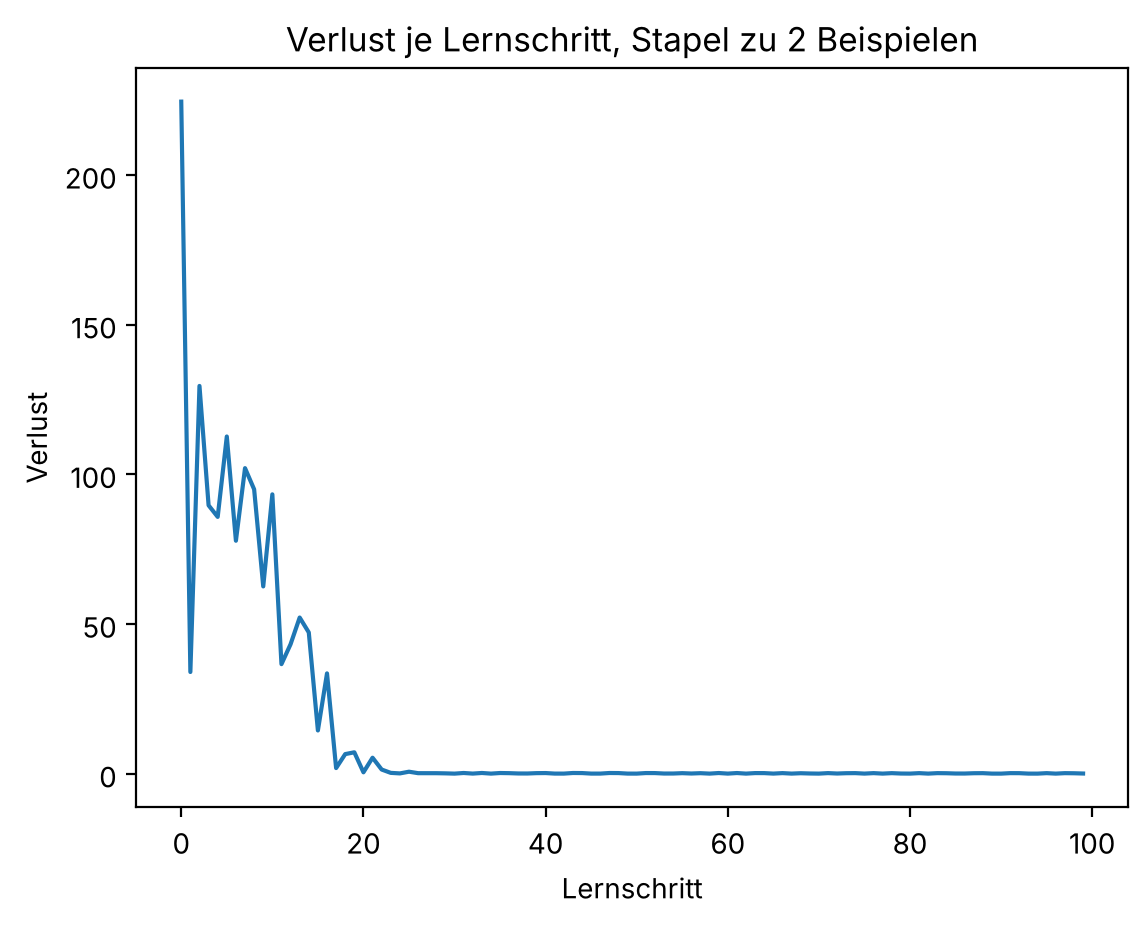

In [20]:
plt.plot(loss_history)
plt.title('Verlust je Lernschritt, Stapel zu 2 Beispielen')
plt.xlabel('Lernschritt')
plt.ylabel('Verlust')
plt.show()

## Zusammenfassung: die fünf Schritte

| Schritt | Code |
|---|---|
| 1 Daten | `X = torch.tensor(x).float().to(device)` |
| 2 Netz | Klasse mit `__init__` (Schichten anlegen) und `forward` (Reihenfolge), dann `mynet = MyNeuralNet().to(device)` |
| 3 Verlust und Optimierer | `loss_func = nn.MSELoss()`, `opt = SGD(mynet.parameters(), lr=0.001)` |
| 4 Training | je Lernschritt: `opt.zero_grad()`, Verlust berechnen, `loss_value.backward()`, `opt.step()` |
| 5 Vorhersage | `mynet(neue_daten)` |

Diese fünf Schritte kommen in jedem Netz wieder, auch bei euren Fotos. Dort ändert sich vor allem Schritt 1 (Fotos statt Zahlenpaare, mit Dataset und DataLoader) und Schritt 2 (ein Netz für Bilder).

## Zum Ausprobieren

Ändert jeweils eine Sache, sagt vorher voraus, was passiert, und führt dann die Trainingszelle in Abschnitt 4 und die Vorhersage in Abschnitt 5 noch einmal aus:

1. Lernrate `lr=0.01` statt `0.001`. Was macht die Kurve?
2. Die Zeile `opt.zero_grad()` weglassen. Wird der Verlust noch kleiner?
3. Eine andere Regel lernen lassen, zum Beispiel `y = 2a + b`. Wie gut trifft das Netz 10 und 11?
4. Ohne `torch.manual_seed(0)` trainieren, mehrmals. Wie stark schwankt die Vorhersage?